# V2 第一部分　止點掃描，找 14° 背屈力臂最大的點

⭐ 計畫在 Obsidian `15 Simulation subjects/V2/00 V2 PLAN — 先選止點，再比路徑.md` §3。

## 0. 📖 故事：為什麼要做這一本

1. Karan 9/18 說，應該先幫每條路徑找背屈（dorsiflexion）最強的止點，再比路徑
2. 第一版兩條都固定接中間楔狀骨（intermediate cuneiform），止點是先選的，不是算出來最好的
3. 這一本只回答三件事
    - IO 接哪裡，14° 的背屈力臂（moment arm）最大
    - CT 接哪裡，14° 的背屈力臂最大
    - 兩條的最佳點一不一樣
4. 已經決定的設定
    - 選點只看 **14°**，走路時踝最多背屈到 +14.3°，力臂在這裡最小，是最吃力的角度
    - 背屈力矩（moment）和中立位 0° 一起列，但不參加選拔
    - P3（支持帶那一點）沿用第一版的規則，IO −5 mm、CT +12 mm
    - 外側楔狀骨（lateral cuneiform）重新定位，用骨頭網格找，不再用代理點

## 1. 設定

### 📖 1.1. 載入引擎和原始模型

1. 引擎 `transfer_engine.py` 是從 `1.Routing/old version 1` 複製過來的，第一版保持不動
2. 原始模型也是複製的，MD5 和第一版一模一樣
3. 下面印出的是引擎從模型讀到的五個止點座標，外側楔狀骨那一格等一下會換掉

In [ ]:
import csv  # 寫 CSV
import math  # 角度換弧度
import os  # 組路徑
import re  # 改 .osim 裡的文字
import sys  # 讓 python 找得到 V2 的引擎

import matplotlib.pyplot as plt  # 畫圖
import numpy as np  # 陣列
import opensim as osim  # OpenSim API
from tqdm import tqdm  # 進度條

ROOT = r"D:\OpenSim 4.6\Tendon transfer model\V2"  # V2 的程式資料夾
MODEL = os.path.join(ROOT, 'model', 'gait2392_simbody_original.osim')  # 原始 Gait2392
GEOMETRY = r"D:\OpenSim 4.6\Geometry"  # OpenSim 安裝附的骨頭網格
FIGURES = os.path.join(ROOT, 'figures')  # 圖存這裡，之後複製到 Obsidian
MODELS_DIR = os.path.join(ROOT, 'models', 'part1')  # 第一部分的 .osim 存這裡
sys.path.insert(0, ROOT)  # 先找 V2 自己的引擎
from transfer_engine import (  # noqa: E402
    TransferEngine, lower_z_default, read_ascii_vtp, via_y_from_height,
)

ROUTES = {'IO': -0.020, 'CT': 0.028}  # 開窗中段點的內外側座標 z，公尺，左腳 +z 是內側
HEIGHT_CM = 7.5  # 開窗高度，內踝尖上方幾公分
VIA_Y = via_y_from_height(HEIGHT_CM)  # 換成模型裡的高度座標
SELECT_ANGLE = 14.0  # 選點用的踝角度
ANGLES = [0.0, SELECT_ANGLE]  # 每個點都算中立位和 14°
PLATEAU_MM = 0.5  # 和最高點差不到這麼多，就算在同一個平台上
COLOURS = {'IO': '#1f77b4', 'CT': '#ff7f0e'}  # 和所有圖同色

engine = TransferEngine(MODEL)  # 載入一次，之後反覆改路徑
print(f'window y {VIA_Y:.4f} m')
for route, via_z in ROUTES.items():
    print(f'{route}: mid point z {via_z * 1000:+.0f} mm, '
          f'P3 z {lower_z_default(via_z) * 1000:+.1f} mm')
for key, info in engine.insertions.items():
    xyz_mm = np.round(np.array(info['xyz']) * 1000, 1)  # 公尺換毫米
    print(f"{key:24s} {xyz_mm} mm  ({info['kind']})")

window y -0.3403 m
IO: mid point z -20 mm, P3 z -5.0 mm
CT: mid point z +28 mm, P3 z +12.0 mm
navicular                [41.7 33.4 28.6] mm  (control)
medial_cuneiform         [116.6  17.8  30.5] mm  (true)
intermediate_cuneiform   [94.6 38.9 10.6] mm  (interpolated)
lateral_cuneiform        [92.2 38.8  0.1] mm  (proxy)
cuboid                   [ 68.1  10.6 -28.4] mm  (proxy)
base_5th_metatarsal      [ 67.7  21.9 -34.3] mm  (true)


### 👀 1.1. 讀出來的設定

1. 開窗高度 y −0.3403 m，就是內踝尖上方 7.5 cm
2. P3 沿用第一版，IO **−5.0 mm**、CT **+12.0 mm**
3. 六個錨點裡，內側楔狀骨和第五蹠骨基底是真止點，中間楔狀骨是內插，外側楔狀骨和骰骨是代理點

## 2. 重新定位外側楔狀骨

### 📖 2.1. 用骨頭網格找它的背側表面

1. 第一版的外側楔狀骨是**代理點**，借伸趾長肌（extensor digitorum longus）經過足背的點，位置是估的
2. OpenSim 安裝資料夾裡有**單獨的骨頭網格**，`third_cuneiform_lv.vtp` 就是左腳的第三楔狀骨，也就是外側楔狀骨
3. 先確認這些網格和模型足部 `l_foot.vtp` 在同一個座標系，每個頂點到足部網格最近的距離要只有幾毫米
4. 再從骨頭中心的正上方往下打一條線，打到的最高點就是**背側表面**，肌腱縫在這裡
5. 中間楔狀骨也用同一個方法算一次，只拿來比較，⚠️ 止點仍用第一版的點，這樣才能對帳

In [ ]:
def load_mesh(name):
    """讀一個骨頭網格，回傳頂點 N×3 和三角形 M×3，單位公尺。"""
    positions, indices = read_ascii_vtp(os.path.join(GEOMETRY, name + '.vtp'))
    return np.array(positions).reshape(-1, 3), np.array(indices).reshape(-1, 3)


def dorsal_surface(vertices, triangles, x, z):
    """從 (x, z) 正上方往下打一條線，回傳打到的最高點 y（Möller–Trumbore）。"""
    origin = np.array([x, 1.0, z])  # 從很高的地方開始
    direction = np.array([0.0, -1.0, 0.0])  # 往下
    a, b, c = (vertices[triangles[:, k]] for k in range(3))  # 三角形的三個角
    edge1, edge2 = b - a, c - a
    p = np.cross(direction, edge2)
    det = (edge1 * p).sum(1)
    usable = np.abs(det) > 1e-12  # 和線平行的三角形跳過
    inv = 1.0 / np.where(usable, det, 1.0)
    offset = origin - a
    u = (offset * p).sum(1) * inv
    q = np.cross(offset, edge1)
    v = (q * direction).sum(1) * inv
    t = (edge2 * q).sum(1) * inv  # 從起點往下走多遠打到
    hit = usable & (u >= 0) & (v >= 0) & (u + v <= 1) & (t > 0)
    return 1.0 - t[hit].min()  # 最先打到的就是最高的表面


foot, _ = load_mesh('l_foot')  # 模型足部網格，只拿來比對座標系
bones = {name: load_mesh(name) for name in (
    'navicular_lv', 'first_cuneiform_lv', 'second_cuneiform_lv',
    'third_cuneiform_lv', 'cuboid_lv', 'metatarsal1_lv', 'metatarsal2_lv',
    'metatarsal3_lv', 'metatarsal4_lv', 'metatarsal5_lv', 'calcaneous_lv',
)}

# 每塊骨頭的頂點到足部網格最近的距離，確認是同一個座標系
for name in ('second_cuneiform_lv', 'third_cuneiform_lv', 'metatarsal3_lv'):
    vertices = bones[name][0]
    nearest = np.sqrt(((vertices[:, None, :] - foot[None, :, :]) ** 2).sum(-1)).min(1)
    print(f'{name:20s} median distance to l_foot {np.median(nearest) * 1000:.1f} mm')

# 外側楔狀骨：骨頭中心正上方的背側表面
vertices, triangles = bones['third_cuneiform_lv']
centre = vertices.mean(0)  # 頂點平均當中心
LATERAL_NEW = (centre[0], dorsal_surface(vertices, triangles, centre[0], centre[2]), centre[2])
LATERAL_OLD = engine.insertions['lateral_cuneiform']['xyz']  # 第一版的代理點

# 中間楔狀骨用同一個方法，只拿來比較
vertices, triangles = bones['second_cuneiform_lv']
centre = vertices.mean(0)
INTERMEDIATE_BONE = (centre[0], dorsal_surface(vertices, triangles, centre[0], centre[2]), centre[2])
INTERMEDIATE_V1 = engine.insertions['intermediate_cuneiform']['xyz']

# 內側楔狀骨也算一次足背表面，第一版的點是脛前肌止點，在骨頭內側偏下
vertices, triangles = bones['first_cuneiform_lv']
centre = vertices.mean(0)
MEDIAL_BONE = (centre[0], dorsal_surface(vertices, triangles, centre[0], centre[2]), centre[2])
MEDIAL_V1 = engine.insertions['medial_cuneiform']['xyz']

# 第三蹠骨的近端，確認外側楔狀骨就在它後面
metatarsal3 = bones['metatarsal3_lv'][0]
base3 = metatarsal3[metatarsal3[:, 0] < metatarsal3[:, 0].min() + 0.005].mean(0)

for label, xyz in (('lateral cuneiform, relocated', LATERAL_NEW),
                   ('lateral cuneiform, V1 proxy', LATERAL_OLD),
                   ('intermediate cuneiform, bone surface', INTERMEDIATE_BONE),
                   ('intermediate cuneiform, V1 anchor', INTERMEDIATE_V1),
                   ('medial cuneiform, dorsal bone surface', MEDIAL_BONE),
                   ('medial cuneiform, V1 anchor (TA insertion)', MEDIAL_V1),
                   ('3rd metatarsal base centre', base3)):
    print(f'{label:44s} {np.round(np.array(xyz) * 1000, 1)} mm')
shift = (np.array(LATERAL_NEW) - np.array(LATERAL_OLD)) * 1000
print(f'relocated minus proxy: {np.round(shift, 1)} mm, distance {np.linalg.norm(shift):.1f} mm')

second_cuneiform_lv  median distance to l_foot 2.7 mm
third_cuneiform_lv   median distance to l_foot 2.5 mm
metatarsal3_lv       median distance to l_foot 2.1 mm
lateral cuneiform, relocated                 [88.6 30.5  0.6] mm
lateral cuneiform, V1 proxy                  [92.2 38.8  0.1] mm
intermediate cuneiform, bone surface         [98.7 34.2 12.6] mm
intermediate cuneiform, V1 anchor            [94.6 38.9 10.6] mm
medial cuneiform, dorsal bone surface        [106.6  29.3  23.3] mm
medial cuneiform, V1 anchor (TA insertion)   [116.6  17.8  30.5] mm
3rd metatarsal base centre                   [102.6  23.7  -8.4] mm
relocated minus proxy: [-3.6 -8.3  0.5] mm, distance 9.1 mm


### 👀 2.1. 外側楔狀骨搬到哪裡

1. ✅ 三塊骨頭到足部網格的中位距離 **2.1 到 2.7 mm**，和模型是同一個座標系
2. ⭐ 新的外側楔狀骨 **(88.6, 30.5, 0.6) mm**，舊的代理點 (92.2, 38.8, 0.1) mm
    - 往後 3.6 mm、**往下 8.3 mm**，內外側幾乎沒動，總共差 9.1 mm
    - 主要是從伸肌腱那條線**降到骨頭表面**
3. 中間楔狀骨的骨頭表面在 (98.7, 34.2, 12.6) mm，第一版的點比它高 4.7 mm
4. ⚠️ 內側楔狀骨的足背表面在 (106.6, 29.3, 23.3) mm，第一版的點 (116.6, 17.8, 30.5) 是脛前肌止點，在它前內側、低 11.5 mm
5. 第三蹠骨近端中心在 x 102.6 mm，外側楔狀骨在它後面，和 Karan 說的「在第三蹠骨底下」一致

### 📖 2.2. 畫出來：新舊兩個外側楔狀骨

1. 從上往下看左腳，x 往前、z 往內側
2. 外側楔狀骨和第三蹠骨塗橄欖黃，中間楔狀骨塗綠
3. ✕ 是第一版的代理點，★ 是重新定位的點

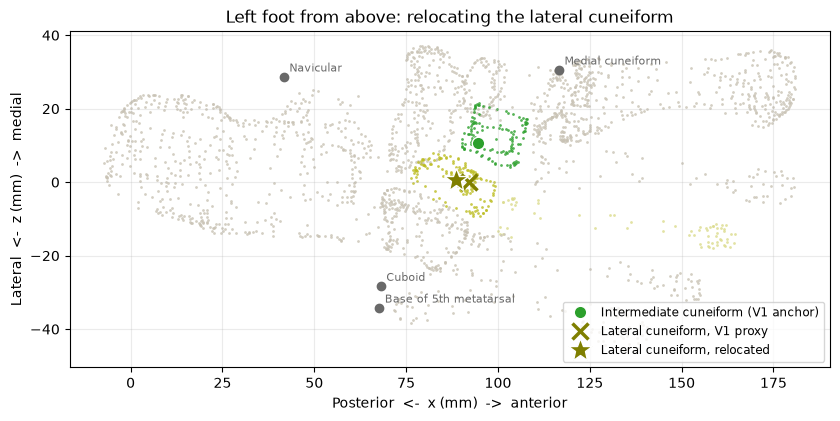

In [ ]:
BONE_STYLE = {  # 每塊骨頭的顏色，其他的畫淺灰
    'third_cuneiform_lv': '#bcbd22', 'metatarsal3_lv': '#dbdb8d',
    'second_cuneiform_lv': '#2ca02c',
}
fig, axis = plt.subplots(figsize=(8.5, 5.2))
for name, (vertices, _) in bones.items():
    colour = BONE_STYLE.get(name, '#c8c2b4')
    axis.scatter(vertices[:, 0] * 1000, vertices[:, 2] * 1000, s=4,
                 color=colour, alpha=0.8, linewidths=0)
for key in ('navicular', 'medial_cuneiform', 'cuboid', 'base_5th_metatarsal'):
    x, _, z = engine.insertions[key]['xyz']
    axis.plot(x * 1000, z * 1000, 'o', color='dimgrey', markersize=6)
    axis.annotate(engine.insertions[key]['label'], (x * 1000, z * 1000),
                  xytext=(4, 4), textcoords='offset points', fontsize=8,
                  color='dimgrey')
axis.plot(INTERMEDIATE_V1[0] * 1000, INTERMEDIATE_V1[2] * 1000, 'o',
          color='#2ca02c', markersize=9, markeredgecolor='white',
          label='Intermediate cuneiform (V1 anchor)')
axis.plot(LATERAL_OLD[0] * 1000, LATERAL_OLD[2] * 1000, 'x', color='#7f7f00',
          markersize=11, markeredgewidth=2.5, label='Lateral cuneiform, V1 proxy')
axis.plot(LATERAL_NEW[0] * 1000, LATERAL_NEW[2] * 1000, '*', color='#7f7f00',
          markersize=18, markeredgecolor='white',
          label='Lateral cuneiform, relocated')
axis.set_aspect('equal')
axis.set_xlabel('Posterior  <-  x (mm)  ->  anterior')
axis.set_ylabel('Lateral  <-  z (mm)  ->  medial')
axis.set_title('Left foot from above: relocating the lateral cuneiform')
axis.legend(loc='lower right', fontsize=8.5)
axis.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'v2-p1-lateral-cuneiform-relocated.png'),
            dpi=200, bbox_inches='tight')
plt.show()

### 👀 2.2. 怎麼讀這張圖

1. 從上面看，★ 和 ✕ 幾乎疊在一起，因為搬動主要是**往下**，上視圖看不到高度
2. ★ 落在橄欖黃的外側楔狀骨正中間，前面是淡黃的第三蹠骨
3. ⚠️ 舟狀骨、骰骨、第五蹠骨基底這三個錨點是第一版模型的點，離骨頭有一段距離，這次沒有動

## 3. 止點折線與掃描點

### 📖 3.1. 六個錨點連成一條線，沿線取點

1. 位置 0 到 5 分別是舟狀骨、內側楔、中間楔、外側楔（新）、骰骨、第五蹠骨基底
2. 兩個錨點中間用直線內插，例如 2.5 就是中間楔和外側楔的正中間
3. 整條線 1 到 5 每 0.25 一點，中間楔到外側楔 2 到 3 每 0.05 一點，重疊的點只算一次
4. 舟狀骨（位置 0）是原生止點，只算一次當對照，不參加選拔

In [ ]:
ANCHORS = [  # (鍵, 圖上的名字, 座標)
    ('navicular', 'Navicular', engine.insertions['navicular']['xyz']),
    ('medial_cuneiform', 'Medial cun', engine.insertions['medial_cuneiform']['xyz']),
    ('intermediate_cuneiform', 'Intermediate cun', INTERMEDIATE_V1),
    ('lateral_cuneiform', 'Lateral cun', LATERAL_NEW),
    ('cuboid', 'Cuboid', engine.insertions['cuboid']['xyz']),
    ('base_5th_metatarsal', '5th MT base', engine.insertions['base_5th_metatarsal']['xyz']),
]


def point_at(position):
    """折線上某個位置的座標，兩個錨點之間直線內插。"""
    low = min(int(math.floor(position)), len(ANCHORS) - 2)  # 左邊的錨點
    fraction = position - low
    start = np.array(ANCHORS[low][2])
    end = np.array(ANCHORS[low + 1][2])
    return tuple(start + fraction * (end - start))


def describe(position):
    """位置換成文字，整數就是錨點名稱。"""
    if abs(position - round(position)) < 1e-9:
        return ANCHORS[int(round(position))][0]
    low = int(math.floor(position))
    return f'{ANCHORS[low][0]}_to_{ANCHORS[low + 1][0]}'


coarse = np.round(np.arange(1.0, 5.0 + 1e-9, 0.25), 2)  # 整條線
dense = np.round(np.arange(2.0, 3.0 + 1e-9, 0.05), 2)  # 中間楔到外側楔加密
POSITIONS = sorted({0.0, *coarse.tolist(), *dense.tolist()})
print(f'{len(coarse)} coarse + {len(dense)} dense - overlap + navicular '
      f'= {len(POSITIONS)} points per route, {2 * len(POSITIONS)} in total')
for position in (0.0, 1.0, 2.0, 2.5, 3.0, 4.0, 5.0):
    print(f'position {position:4.2f}  {describe(position):40s} '
          f'{np.round(np.array(point_at(position)) * 1000, 1)} mm')

17 coarse + 21 dense - overlap + navicular = 34 points per route, 68 in total
position 0.00  navicular                                [41.7 33.4 28.6] mm
position 1.00  medial_cuneiform                         [116.6  17.8  30.5] mm
position 2.00  intermediate_cuneiform                   [94.6 38.9 10.6] mm
position 2.50  intermediate_cuneiform_to_lateral_cuneiform [91.6 34.7  5.6] mm
position 3.00  lateral_cuneiform                        [88.6 30.5  0.6] mm
position 4.00  cuboid                                   [ 68.1  10.6 -28.4] mm
position 5.00  base_5th_metatarsal                      [ 67.7  21.9 -34.3] mm


### 👀 3.1. 掃描點

1. 整條線 17 點、加密 21 點、重疊 5 點、加上舟狀骨，**每條路徑 34 點，共 68 點**
2. 2.5 就是中間楔和外側楔的正中間，(91.6, 34.7, 5.6) mm
3. ⚠️ 中間楔到外側楔這一段，高度從 38.9 降到 30.5 mm，所以這一段的變化同時包含往外和往下，§5.2 會拆開看

## 4. 驗證，先過了才看結果

### 📖 4.1. 對帳第一版

1. 中間楔狀骨、第一版路徑研究的高度 y −0.340，14° 力臂要重現 IO **26.46**、CT **17.40** mm
2. 中立位要重現 IO **32.29**、CT **26.13** mm
3. 再換成這次用的 7.5 cm（y −0.3403），看差多少

In [ ]:
V1_EXPECTED = {'IO': (32.29, 26.46), 'CT': (26.13, 17.40)}  # 第一版 notebook §11.2 印出的 0° 和 14°
for route, via_z in ROUTES.items():
    engine.set_route(via_z, -0.34, insertion=INTERMEDIATE_V1)  # 第一版的高度
    old = engine.sweep_ankle(ANGLES)
    engine.set_route(via_z, VIA_Y, insertion=INTERMEDIATE_V1)  # 這次的高度
    new = engine.sweep_ankle(ANGLES)
    for index, angle in enumerate(ANGLES):
        expected = V1_EXPECTED[route][index]
        got = old[index]['arm_ankle_mm']
        status = 'OK' if abs(got - expected) < 0.01 else 'CHECK'
        print(f'{route} {angle:4.0f} deg: V1 height {got:6.2f} mm (expected {expected:.2f}) {status}, '
              f'7.5 cm {new[index]["arm_ankle_mm"]:6.2f} mm')

IO    0 deg: V1 height  32.29 mm (expected 32.29) OK, 7.5 cm  32.29 mm
IO   14 deg: V1 height  26.46 mm (expected 26.46) OK, 7.5 cm  26.46 mm
CT    0 deg: V1 height  26.13 mm (expected 26.13) OK, 7.5 cm  26.13 mm
CT   14 deg: V1 height  17.40 mm (expected 17.40) OK, 7.5 cm  17.40 mm


### 👀 4.1. 對帳結果

1. ✅ 四個數字全部重現第一版，IO **32.29 / 26.46**、CT **26.13 / 17.40** mm
2. ✅ 高度從 −0.340 換成 −0.3403，力臂在小數第二位都沒變
3. 所以這一本和第一版用的是同一套計算，差別只來自止點

### 📖 4.2. 力臂用另一個方法再算一次

1. `computeMomentArm` 是 OpenSim 內建的
2. 另一個方法是看肌腱長度：踝轉一點點，長度變多少，力臂 ＝ −長度變化 ÷ 角度變化
3. 兩個方法差要小於 0.01 mm

In [ ]:
def arm_from_length(angle_deg, step_deg=0.01):
    """踝往前後各轉一點點，用肌腱長度的變化算力臂，毫米。"""
    lengths = []
    for sign in (-1, 1):
        engine._pose(angle_deg + sign * step_deg, 0.0)
        lengths.append(engine.donor.getGeometryPath().getLength(engine.state))
    return -(lengths[1] - lengths[0]) / math.radians(2 * step_deg) * 1000


for route, via_z in ROUTES.items():
    engine.set_route(via_z, VIA_Y, insertion=LATERAL_NEW)  # 用新的外側楔狀骨測
    builtin = engine.sweep_ankle([SELECT_ANGLE])[0]['arm_ankle_mm']
    by_length = arm_from_length(SELECT_ANGLE)
    print(f'{route} lateral cuneiform 14 deg: computeMomentArm {builtin:.4f} mm, '
          f'from length {by_length:.4f} mm, difference {abs(builtin - by_length):.4f} mm')

IO lateral cuneiform 14 deg: computeMomentArm 32.0066 mm, from length 32.0066 mm, difference 0.0000 mm
CT lateral cuneiform 14 deg: computeMomentArm 18.0814 mm, from length 18.0814 mm, difference 0.0000 mm


### 👀 4.2. 兩個方法一不一樣

1. ✅ 新的外側楔狀骨，14° 時 IO **32.0066**、CT **18.0814** mm，兩個方法差 **0.0000 mm**
2. 所以力臂不是 OpenSim 內部某個設定算出來的巧合，肌腱長度變化本身就是這樣

## 5. 掃描

### 📖 5.1. 每條路徑、每個點都算一次

1. 每一個點：改止點 → 引擎自動重調肌腱鬆弛長度（tendon slack length）→ 算中立位和 14°
2. 記下背屈力臂、背屈力矩（活化度 1.0）、旋後（supination）力臂
3. 結果存成 `V2_part1_attachment_sweep.csv`

In [ ]:
rows = []
for route, via_z in ROUTES.items():
    for position in tqdm(POSITIONS, desc=f'{route} sweep'):
        xyz = point_at(position)
        engine.set_route(via_z, VIA_Y, insertion=xyz)  # P3 用第一版的規則
        result = engine.sweep_ankle(ANGLES)  # 中立位和 14°
        row = {
            'route': route,
            'position': position,
            'insertion': describe(position),
            'x_mm': xyz[0] * 1000,
            'y_mm': xyz[1] * 1000,
            'z_mm': xyz[2] * 1000,
            'p3_mm': engine.lower_z * 1000,
            'tendon_slack_mm': engine.donor.getTendonSlackLength() * 1000,
        }
        for index, angle in enumerate(ANGLES):
            tag = f'{angle:.0f}deg'
            row[f'dorsi_arm_{tag}_mm'] = result[index]['arm_ankle_mm']
            row[f'dorsi_moment_{tag}_Nm'] = result[index]['moment_ankle_nm']
            row[f'supination_arm_{tag}_mm'] = result[index]['arm_subtalar_mm']
        rows.append(row)  # 記憶體裡保留完整精度，寫檔時才四捨五入


def rounded(row):
    """寫進 CSV 用的版本，數字留四位小數。"""
    return {key: (round(value, 4) if isinstance(value, float) else value)
            for key, value in row.items()}


CSV_PATH = os.path.join(ROOT, 'V2_part1_attachment_sweep.csv')
with open(CSV_PATH, 'w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows([rounded(row) for row in rows])
print(len(rows), 'rows saved to', CSV_PATH)

68 rows saved to D:\OpenSim 4.6\Tendon transfer model\V2\V2_part1_attachment_sweep.csv


### 👀 5.1. 掃描完成

1. 68 列存進 `V2_part1_attachment_sweep.csv`，每列一個止點，數字留四位小數
2. 欄位
    - `dorsi_arm_0deg_mm`、`dorsi_arm_14deg_mm` 背屈力臂
    - `dorsi_moment_*_Nm` 背屈力矩，活化度 1.0
    - `supination_arm_*_mm` 旋後力臂，第二部分會用
    - `tendon_slack_mm` 每個點重調後的肌腱鬆弛長度

### 📖 5.2. 高度的慣例會不會改變排名

1. 第一版的中間楔狀骨在伸肌腱那一條線上，比骨頭表面高幾毫米
2. 新的外側楔狀骨是貼在骨頭表面
3. 兩個慣例混在一條線上，所以多算幾個點當對照
    - 中間楔狀骨改貼骨頭表面
    - 外側楔狀骨抬到第一版中間楔狀骨的高度
    - ⭐ 內側楔狀骨改到足背表面，第一版的點是脛前肌的止點，在骨頭內側偏下，而 CT 的最佳點剛好就是它

In [ ]:
lifted_lateral = (LATERAL_NEW[0], INTERMEDIATE_V1[1], LATERAL_NEW[2])  # 抬到肌腱線的高度
checks = {
    'medial, V1 anchor (TA insertion)': MEDIAL_V1,
    'medial, dorsal bone surface': MEDIAL_BONE,
    'intermediate, V1 anchor': INTERMEDIATE_V1,
    'intermediate, bone surface': INTERMEDIATE_BONE,
    'lateral, bone surface (used)': LATERAL_NEW,
    'lateral, lifted to tendon line': lifted_lateral,
}
sensitivity = {}
for route, via_z in ROUTES.items():
    for label, xyz in checks.items():
        engine.set_route(via_z, VIA_Y, insertion=xyz)
        arm = engine.sweep_ankle([SELECT_ANGLE])[0]['arm_ankle_mm']
        sensitivity[(route, label)] = arm
        print(f'{route} {label:34s} 14 deg dorsiflexion arm {arm:6.2f} mm')

IO medial, V1 anchor (TA insertion)   14 deg dorsiflexion arm  26.52 mm
IO medial, dorsal bone surface        14 deg dorsiflexion arm  25.22 mm
IO intermediate, V1 anchor            14 deg dorsiflexion arm  26.46 mm
IO intermediate, bone surface         14 deg dorsiflexion arm  27.41 mm
IO lateral, bone surface (used)       14 deg dorsiflexion arm  32.01 mm
IO lateral, lifted to tendon line     14 deg dorsiflexion arm  29.07 mm
CT medial, V1 anchor (TA insertion)   14 deg dorsiflexion arm  24.65 mm
CT medial, dorsal bone surface        14 deg dorsiflexion arm  23.32 mm
CT intermediate, V1 anchor            14 deg dorsiflexion arm  17.40 mm
CT intermediate, bone surface         14 deg dorsiflexion arm  20.98 mm
CT lateral, bone surface (used)       14 deg dorsiflexion arm  18.08 mm
CT lateral, lifted to tendon line     14 deg dorsiflexion arm  11.19 mm


### 👀 5.2. 高度慣例會不會改變排名

| 14° 背屈力臂 mm | IO | CT |
|---|---|---|
| 內側楔，第一版的點（脛前肌止點） | 26.52 | **24.65** |
| 內側楔，足背骨頭表面 | 25.22 | **23.32** |
| 中間楔，第一版的點（肌腱線） | 26.46 | 17.40 |
| 中間楔，骨頭表面 | 27.41 | 20.98 |
| ⭐ 外側楔，骨頭表面（這次用的） | **32.01** | 18.08 |
| 外側楔，抬到肌腱線 | 29.07 | 11.19 |

1. ⚠️ **高度影響很大**，CT 外側楔從骨頭表面抬到肌腱線，力臂從 18.08 掉到 11.19 mm
2. ✅ **三個楔狀骨都放在骨頭表面比**
    - IO　外側 32.01 > 中間 27.41 > 內側 25.22，外側最大
    - CT　內側 23.32 > 中間 20.98 > 外側 18.08，內側最大
3. ✅ 都放在肌腱線那個高度，IO 外側 29.07 一樣大於中間 26.46
4. 所以「IO 偏外側、CT 偏內側」這個結論，不是錨點高度混在一起造成的

## 6. 誰最大

### 📖 6.1. 每條路徑的最高點和平台

1. 舟狀骨不參加，只從位置 1 到 5 裡面挑
2. **最高點**　14° 背屈力臂最大的那一個位置
3. **平台**　和最高點差不到 0.5 mm 的位置範圍，代表在這個範圍裡接哪裡都差不多
4. 另外列出 B 組合，兩條平均最大的那一點，和 14° 力矩最大的點（只當參考）

In [ ]:
def pick(route, column='dorsi_arm_14deg_mm'):
    """回傳這條路徑在某一欄的最高點和平台範圍。"""
    candidates = [row for row in rows if row['route'] == route and row['position'] >= 1]
    best = max(candidates, key=lambda row: row[column])
    plateau = [row['position'] for row in candidates
               if best[column] - row[column] < PLATEAU_MM]
    return best, min(plateau), max(plateau)


BEST = {}
for route in ROUTES:
    best, low, high = pick(route)
    BEST[route] = best
    print(f"{route}: best position {best['position']:.2f} ({best['insertion']}), "
          f"arm 14 deg {best['dorsi_arm_14deg_mm']:.2f} mm, 0 deg {best['dorsi_arm_0deg_mm']:.2f} mm, "
          f"moment 14 deg {best['dorsi_moment_14deg_Nm']:.2f} Nm")
    print(f'    plateau within {PLATEAU_MM} mm: position {low:.2f} to {high:.2f}')
    by_moment, _, _ = pick(route, 'dorsi_moment_14deg_Nm')
    print(f"    for reference, largest 14 deg moment at {by_moment['position']:.2f} "
          f"({by_moment['dorsi_moment_14deg_Nm']:.2f} Nm)")

# B：兩條平均最大
common = {}
for row in rows:
    if row['position'] >= 1:
        common.setdefault(row['position'], []).append(row['dorsi_arm_14deg_mm'])
COMMON_BEST = max(common, key=lambda position: np.mean(common[position]))
print(f'B, common point: position {COMMON_BEST:.2f} ({describe(COMMON_BEST)}), '
      f'IO {common[COMMON_BEST][0]:.2f} mm, CT {common[COMMON_BEST][1]:.2f} mm')

# 六個錨點的表
print('\nanchors, 14 deg dorsiflexion arm (mm) / moment (Nm)')
for index, (key, _, _) in enumerate(ANCHORS):
    parts = []
    for route in ROUTES:
        row = next(r for r in rows if r['route'] == route and r['position'] == index)
        parts.append(f"{route} {row['dorsi_arm_14deg_mm']:6.2f} / {row['dorsi_moment_14deg_Nm']:6.2f}")
    print(f'  {index} {key:24s} ' + '   '.join(parts))

IO: best position 2.75 (intermediate_cuneiform_to_lateral_cuneiform), arm 14 deg 32.37 mm, 0 deg 33.69 mm, moment 14 deg 30.31 Nm
    plateau within 0.5 mm: position 2.55 to 3.00
    for reference, largest 14 deg moment at 2.80 (30.32 Nm)
CT: best position 1.00 (medial_cuneiform), arm 14 deg 24.65 mm, 0 deg 29.14 mm, moment 14 deg 24.00 Nm
    plateau within 0.5 mm: position 1.00 to 1.25
    for reference, largest 14 deg moment at 1.25 (24.07 Nm)
B, common point: position 1.00 (medial_cuneiform), IO 26.52 mm, CT 24.65 mm

anchors, 14 deg dorsiflexion arm (mm) / moment (Nm)
  0 navicular                IO   6.57 /   8.13   CT   7.37 /   9.09
  1 medial_cuneiform         IO  26.52 /  25.17   CT  24.65 /  24.00
  2 intermediate_cuneiform   IO  26.46 /  25.92   CT  17.40 /  18.63
  3 lateral_cuneiform        IO  32.01 /  30.13   CT  18.08 /  19.46
  4 cuboid                   IO  19.04 /  20.34   CT  13.63 /  15.17
  5 base_5th_metatarsal      IO  12.09 /  13.86   CT   7.98 /   9.39


### 👀 6.1. 答案

1. ⭐⭐ **IO 最強在位置 2.75**，中間楔往外側楔四分之三的地方
    - 14° 力臂 **32.37 mm**，中立位 33.69 mm，14° 力矩 30.31 Nm
    - 平台從 **2.55 到 3.00**，外側楔狀骨（3.00，32.01 mm）也在平台裡
    - ✅ 和 Karan 猜的外側楔狀骨一致
2. ⭐⭐ **CT 最強在內側楔狀骨**（位置 1.00）
    - 14° 力臂 **24.65 mm**，中立位 29.14 mm，14° 力矩 24.00 Nm
    - 平台 1.00 到 1.25，接外側楔狀骨只有 18.08 mm
    - ⛔ 和 Karan 猜的不一樣
3. ⭐ **兩條的最佳點不一樣**，所以第二部分 A 組合是 IO 接 2.75、CT 接內側楔
4. B 組合（兩條平均最大）是**內側楔狀骨**，IO 26.52、CT 24.65 mm
5. 用 14° 力矩挑，IO 2.80、CT 1.25，和力臂挑的只差一格，結論一樣

### 📖 6.2. 畫圖一：背屈力臂沿著止點線

1. 橫軸是止點位置，由內側往外側
2. 實線 14°、虛線中立位，IO 藍、CT 橘
3. ★ 是 14° 的最高點，淡色帶是平台，灰底是加密的那一段

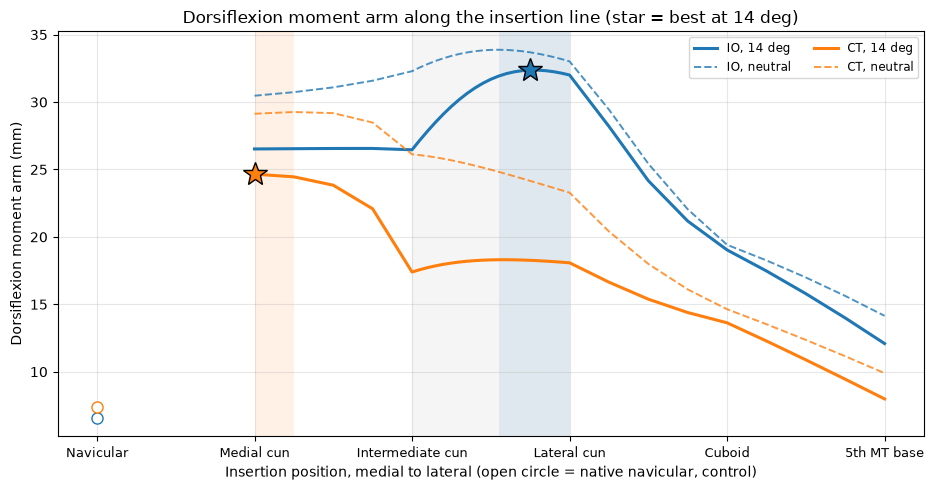

In [ ]:
TICKS = [index for index in range(len(ANCHORS))]
TICK_LABELS = [label for _, label, _ in ANCHORS]


def along_line(column_14, column_0, ylabel, title, filename, mark_best=True):
    """沿止點線畫一個量，兩條路徑、兩個角度。"""
    fig, axis = plt.subplots(figsize=(9.5, 5.0))
    axis.axvspan(2, 3, color='grey', alpha=0.08, linewidth=0)  # 加密的那一段
    for route in ROUTES:
        mine = [row for row in rows if row['route'] == route and row['position'] >= 1]
        x = [row['position'] for row in mine]
        axis.plot(x, [row[column_14] for row in mine], '-', color=COLOURS[route],
                  linewidth=2.2, label=f'{route}, 14 deg')
        axis.plot(x, [row[column_0] for row in mine], '--', color=COLOURS[route],
                  linewidth=1.4, alpha=0.8, label=f'{route}, neutral')
        control = next(row for row in rows if row['route'] == route and row['position'] == 0)
        axis.plot(0, control[column_14], 'o', markerfacecolor='white',
                  markeredgecolor=COLOURS[route], markersize=8)  # 舟狀骨對照
        if mark_best:
            best, low, high = pick(route)
            axis.axvspan(low, high, color=COLOURS[route], alpha=0.10, linewidth=0)
            axis.plot(best['position'], best[column_14], '*', color=COLOURS[route],
                      markersize=18, markeredgecolor='black', zorder=5)
    axis.set_xticks(TICKS)
    axis.set_xticklabels(TICK_LABELS, fontsize=9)
    axis.set_xlabel('Insertion position, medial to lateral (open circle = native navicular, control)')
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8.5, ncol=2)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES, filename), dpi=200, bbox_inches='tight')
    plt.show()


along_line('dorsi_arm_14deg_mm', 'dorsi_arm_0deg_mm', 'Dorsiflexion moment arm (mm)',
           'Dorsiflexion moment arm along the insertion line (star = best at 14 deg)',
           'v2-p1-dorsi-arm-along-insertions.png')

### 👀 6.2. 怎麼讀圖一

1. ⭐ **藍色實線**從內側楔到中間楔幾乎是平的（約 26.5 mm），進入加密段之後往上爬，在 2.75 到頂
2. ⭐ **橘色實線**從內側楔開始一路往下，過了中間楔掉到 17 到 18 mm，所以 CT 的最佳點在最內側
3. 虛線（中立位）的形狀和實線一樣，IO 在 2.5 附近最高、CT 在 1.25 附近最高，**換成中立位選也是同樣的區域**
4. 往骰骨和第五蹠骨，兩條都一路下降，外側止點背屈力臂最小
5. 左下的空心圓是舟狀骨（原生止點），只有 6.6 到 7.4 mm，所以轉位到足背本身就是背屈力臂的來源

### 📖 6.3. 畫圖二：背屈力矩，只當參考

1. 同一個版面，換成活化度 1.0 的背屈力矩
2. 力矩 ＝ 肌力 × 力臂，肌力會隨止點變，因為肌腱鬆弛長度每次都重調
3. ⚠️ 選點看圖一，這張不參加選拔

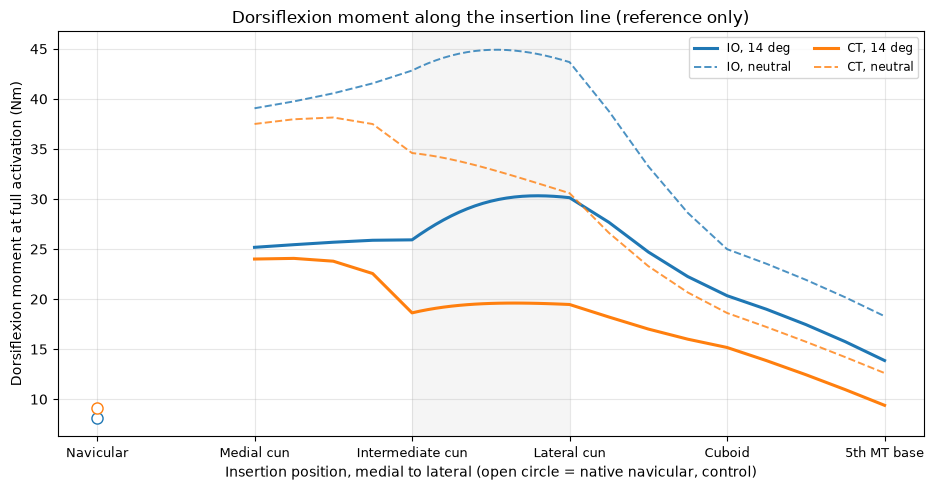

In [ ]:
along_line('dorsi_moment_14deg_Nm', 'dorsi_moment_0deg_Nm', 'Dorsiflexion moment at full activation (Nm)',
           'Dorsiflexion moment along the insertion line (reference only)',
           'v2-p1-dorsi-moment-along-insertions.png', mark_best=False)

### 👀 6.3. 怎麼讀圖二

1. 力矩的形狀和力臂一樣，IO 高點在中間楔和外側楔之間，CT 高點在內側楔
2. 14° 時 IO 最高 30.3 Nm、CT 最高 24.1 Nm
3. ⚠️ 只當參考，選點用圖一

### 📖 6.4. 曲線有沒有跳

1. 加密那一段每 0.05 一點，相鄰兩點的力臂不應該跳超過 1 mm
2. 跳了就代表某一個路徑點在那裡繞過去，要回頭查

In [ ]:
for route in ROUTES:
    mine = [row for row in rows if row['route'] == route and 2 <= row['position'] <= 3]
    for column in ('dorsi_arm_0deg_mm', 'dorsi_arm_14deg_mm'):
        values = np.array([row[column] for row in mine])
        jump = np.abs(np.diff(values)).max()
        print(f'{route} {column:20s} largest step between neighbours {jump:.3f} mm '
              f'{"OK" if jump < 1 else "CHECK"}')

IO dorsi_arm_0deg_mm    largest step between neighbours 0.280 mm OK
IO dorsi_arm_14deg_mm   largest step between neighbours 0.719 mm OK
CT dorsi_arm_0deg_mm    largest step between neighbours 0.175 mm OK
CT dorsi_arm_14deg_mm   largest step between neighbours 0.175 mm OK


### 👀 6.4. 曲線連續

1. ✅ 相鄰兩點最大只跳 **0.72 mm**（IO，14°），都小於 1 mm
2. 所以加密段裡沒有路徑點突然繞過去，最高點是真的最高點，不是跳動造成的

### 📖 6.5. 畫圖三：在腳上看每個止點的力臂

1. 從上面看左腳，每一個掃描點塗上它 14° 的背屈力臂，越黃越大
2. 左邊 IO、右邊 CT，同一個色階，可以直接比
3. ★ 是最佳點

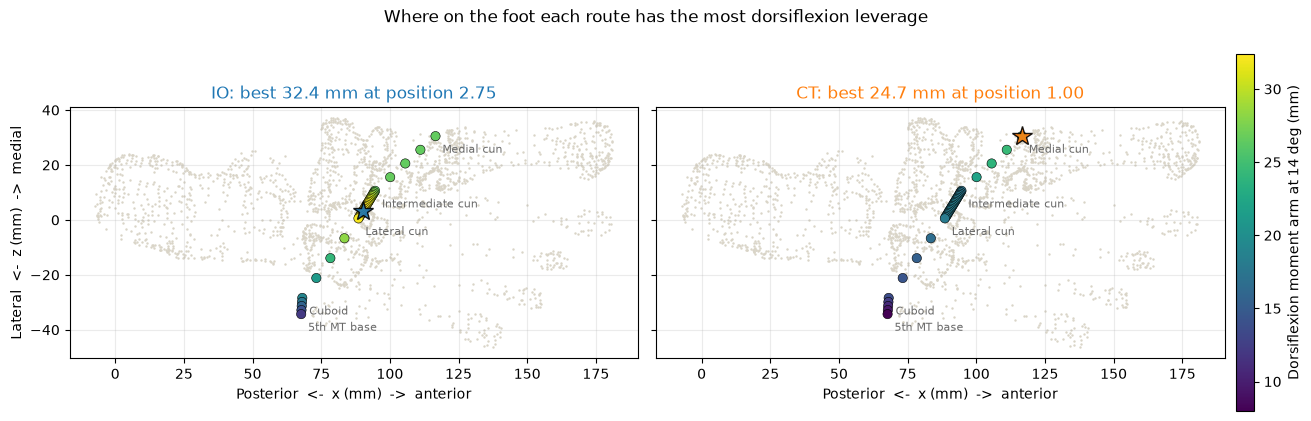

In [ ]:
all_arms = [row['dorsi_arm_14deg_mm'] for row in rows if row['position'] >= 1]
norm = plt.Normalize(min(all_arms), max(all_arms))  # 兩張圖同一個色階
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True, constrained_layout=True)
for axis, route in zip(axes, ROUTES):
    for vertices, _ in bones.values():  # 骨頭當背景
        axis.scatter(vertices[:, 0] * 1000, vertices[:, 2] * 1000, s=3,
                     color='#d9d4c7', linewidths=0)
    mine = [row for row in rows if row['route'] == route and row['position'] >= 1]
    points = axis.scatter([row['x_mm'] for row in mine], [row['z_mm'] for row in mine],
                          c=[row['dorsi_arm_14deg_mm'] for row in mine], cmap='viridis',
                          norm=norm, s=45, edgecolors='black', linewidths=0.4, zorder=3)
    best = BEST[route]
    axis.plot(best['x_mm'], best['z_mm'], '*', color=COLOURS[route], markersize=15,
              markeredgecolor='black', alpha=0.9, zorder=4)
    for key, label, xyz in ANCHORS[1:]:
        axis.annotate(label, (xyz[0] * 1000, xyz[2] * 1000), xytext=(5, -12),
                      textcoords='offset points', fontsize=8, color='dimgrey')
    axis.set_aspect('equal')
    axis.set_title(f"{route}: best {best['dorsi_arm_14deg_mm']:.1f} mm at position {best['position']:.2f}",
                   color=COLOURS[route])
    axis.set_xlabel('Posterior  <-  x (mm)  ->  anterior')
    axis.grid(alpha=0.25)
axes[0].set_ylabel('Lateral  <-  z (mm)  ->  medial')
fig.colorbar(points, ax=axes, shrink=0.9, pad=0.01, label='Dorsiflexion moment arm at 14 deg (mm)')
fig.suptitle('Where on the foot each route has the most dorsiflexion leverage')
plt.savefig(os.path.join(FIGURES, 'v2-p1-foot-map-dorsi-arm.png'), dpi=200, bbox_inches='tight')
plt.show()

### 👀 6.5. 怎麼讀圖三

1. ⭐ **IO（左）** 最黃的點在中間楔和外側楔之間，★ 在外側楔狀骨前內側一點
2. ⭐ **CT（右）** 最黃的點在內側楔狀骨，往外側顏色一路變深
3. 兩張同一個色階，CT 整體比 IO 深，同一個止點 CT 的背屈力臂幾乎都比較小
4. 往骰骨、第五蹠骨兩條都變成深紫，外側止點不適合拿來背屈

## 7. 存成 OpenSim GUI 打得開的模型

### 📖 7.1. 每一個掃描點一個 .osim

1. 每一個點重新設路徑，擺回中立位，轉位肌塗顏色（IO 藍、CT 橘），存檔
2. 存完馬上**重新載入**，不改任何東西再算一次，和上面的數字差要是 0
3. 檔名沒有 `+`，OpenSim 不收
4. `models_index.csv` 一列一個檔，寫著參數和數字

In [ ]:
os.makedirs(MODELS_DIR, exist_ok=True)


def rgb(colour):
    """#rrggbb 換成 OpenSim 的 Vec3。"""
    colour = colour.lstrip('#')
    return osim.Vec3(*(int(colour[i:i + 2], 16) / 255 for i in (0, 2, 4)))


def file_stem(route, position):
    return f'V2_P1_{route}_pos{position:.2f}_{describe(position)}'


index_rows, worst = [], 0.0
for row in tqdm(rows, desc='save and reload'):
    route, position = row['route'], row['position']
    engine.set_route(ROUTES[route], VIA_Y, insertion=point_at(position))
    engine._pose(0.0, 0.0)  # 存檔前擺回中立位
    engine.donor.getGeometryPath().upd_Appearance().set_color(rgb(COLOURS[route]))
    stem = file_stem(route, position)
    engine.model.setName(stem)
    path = os.path.join(MODELS_DIR, stem + '.osim')
    engine.model.printToXML(path)

    fresh = TransferEngine(path)  # 重新載入，不改路徑
    again = fresh.sweep_ankle(ANGLES)
    gap = max(abs(again[0]['arm_ankle_mm'] - row['dorsi_arm_0deg_mm']),
              abs(again[1]['arm_ankle_mm'] - row['dorsi_arm_14deg_mm']),
              abs(fresh.donor.getTendonSlackLength() * 1000 - row['tendon_slack_mm']))
    worst = max(worst, gap)
    index_rows.append({'file': stem + '.osim', **rounded(row), 'reload_difference_mm': gap})

with open(os.path.join(MODELS_DIR, 'models_index.csv'), 'w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(index_rows[0]))
    writer.writeheader()
    writer.writerows(index_rows)
print(f'{len(index_rows)} models saved, largest reload difference {worst:.2e} mm')

68 models saved, largest reload difference 0.00e+00 mm


### 👀 7.1. 68 個模型

1. 68 個 `.osim` 存在 `V2\models\part1\`，IO 藍、CT 橘
2. ✅ 每個都重新載入再算一次，最大差異 **0.00e+00 mm**，和上面的數字完全一樣
3. `models_index.csv` 一列一個檔，`file` 欄就是檔名，數字和上面的 CSV 一樣
4. 在 GUI 對帳：`File → Open Model` 打開 `V2_P1_IO_pos2.75_...osim`，`Tools → Plot` 畫 `tib_post_l` 對 `ankle_angle_l` 的 moment arm，14° 那一點要是 32.37 mm

### 📖 7.2. 上色的總覽模型，一條路徑一個

1. 六個錨點放進同一個模型，每條一種顏色，和第一版 `model-view-attachment.png` 同色
2. ⭐ 14° 最佳點用青色，如果剛好是錨點，就把那個錨點改成青色
3. ⛔ 同一個模型裡有好幾條轉位肌，**只能拿來看**，不能跑分析

In [ ]:
ANCHOR_COLOURS = ['#7f7f7f', '#1f77b4', '#2ca02c', '#bcbd22', '#e377c2', '#9467bd']
BEST_COLOUR = '#17becf'


def muscle_block(path):
    """讀出一個 .osim 裡 tib_post_l 的整段 XML，和整份文字。"""
    text = open(path, encoding='utf-8').read()
    start = text.index('<Thelen2003Muscle name="tib_post_l">')
    end = text.index('</Thelen2003Muscle>', start) + len('</Thelen2003Muscle>')
    return text, text[start:end], start, end


def recolour(block, name, colour):
    """改肌肉和路徑點的名字，換顏色。"""
    block = block.replace('name="tib_post_l"', f'name="{name}"', 1)
    block = block.replace('name="tib_post_l-P', f'name="{name}-P')
    colour = colour.lstrip('#')
    red, green, blue = (int(colour[i:i + 2], 16) / 255 for i in (0, 2, 4))
    return re.sub(r'<color>[^<]*</color>', f'<color>{red:.4f} {green:.4f} {blue:.4f}</color>', block, count=1)


for route in ROUTES:
    best_position = BEST[route]['position']
    members = [(index, f'tib_post_l_{key}', colour)
               for index, ((key, _, _), colour) in enumerate(zip(ANCHORS, ANCHOR_COLOURS))]
    members = [(p, (n + '_BEST' if p == best_position else n), (BEST_COLOUR if p == best_position else c))
               for p, n, c in members]
    if best_position not in [p for p, _, _ in members]:
        members.append((best_position, f'tib_post_l_BEST_pos{best_position:.2f}', BEST_COLOUR))
    base_text, _, start, end = muscle_block(os.path.join(MODELS_DIR, file_stem(route, best_position) + '.osim'))
    blocks = [recolour(muscle_block(os.path.join(MODELS_DIR, file_stem(route, p) + '.osim'))[1], n, c)
              for p, n, c in members]
    text = base_text[:start] + '\n\t\t\t\t'.join(blocks) + base_text[end:]
    text = re.sub(r'<Model name="[^"]*">', f'<Model name="V2_P1_{route}_overview_view_only">', text, count=1)
    out = os.path.join(MODELS_DIR, f'V2_P1_{route}_overview_VIEW_ONLY.osim')
    open(out, 'w', encoding='utf-8').write(text)

    check = osim.Model(out)  # 重新載入，確認每一條都在
    check.initSystem()
    names = [check.getMuscles().get(i).getName() for i in range(check.getMuscles().getSize())]
    found = [n for _, n, _ in members if n in names]
    print(f'{route} overview: {len(found)} of {len(members)} coloured paths, '
          f'best = {[n for _, n, _ in members if "BEST" in n][0]}')

IO overview: 7 of 7 coloured paths, best = tib_post_l_BEST_pos2.75
CT overview: 6 of 6 coloured paths, best = tib_post_l_medial_cuneiform_BEST


### 👀 7.2. 兩個總覽模型

1. `V2_P1_IO_overview_VIEW_ONLY.osim` 有 **7 條**，六個錨點加上 2.75 的最佳點（青色）
2. `V2_P1_CT_overview_VIEW_ONLY.osim` 有 **6 條**，最佳點剛好是內側楔狀骨，所以那一條改成青色
3. 顏色　舟狀骨灰、內側楔藍、中間楔綠、外側楔橄欖黃、骰骨粉紅、第五蹠骨紫、最佳點青
4. ⛔ 同一個模型裡有好幾條轉位肌，**只能看，不能跑分析**